<h1 style="color:orange; font-weight:bold">Step 1 — Import Libraries</h1>

In [1]:
# Import Libraries
import numpy as np
import pandas as pd

<h1 style="color:orange; font-weight:bold">Step 2 — Dataset</h1>

In [2]:
# Load Dataset & Save into Variable (df)
# 'low_memory=False' Makes Pandas read the Whole file at Once, To Avoid 'DtypeWarning'
df = pd.read_csv("/home/kali/green-taxi-fare-prediction/data/raw/2015_Green_Taxi_Trip_Data.csv", low_memory=False)

FileNotFoundError: [Errno 2] No such file or directory: '/home/kali/green-taxi-fare-prediction/data/raw/2015_Green_Taxi_Trip_Data.csv'

In [ ]:
# Total : COlumns & Rows
print("Shape:")
print(df.shape)

# DataTypes of Each Columns
print("\nDatatypes :")
print(df.dtypes)

Shape:
(759830, 21)

Datatypes :
vendorid                     str
pickup_datetime              str
dropoff_datetime             str
Store_and_fwd_flag           str
rate_code                float64
Pickup_longitude             str
Pickup_latitude          float64
Dropoff_longitude        float64
Dropoff_latitude         float64
Passenger_count          float64
Trip_distance            float64
Fare_amount              float64
Extra                    float64
MTA_tax                  float64
Tip_amount               float64
Tolls_amount             float64
Ehail_fee                float64
Improvement_surcharge    float64
Total_amount             float64
Payment_type             float64
Trip_type                float64
dtype: object


In [ ]:
# Convert 'Pickup_longitude' & 'vendorid' to 'float64' from 'str' 
df["Pickup_longitude"] = pd.to_numeric(df["Pickup_longitude"], errors="coerce")
print("'Pickup_longitude' :", df["Pickup_longitude"].dtypes)
df["vendorid"] = pd.to_numeric(df["vendorid"], errors="coerce")
print("'vendorid'         :", df["vendorid"].dtypes)

'Pickup_longitude' : float64
'vendorid'         : float64


<h1 style="color:orange; font-weight:bold">Step 3 — Data Understanding</h1>

<h3 style="color:green; font-weight:bold">3.1 — First look</h3>

In [ ]:
# 1. Display the first 5 rows of the DataFrame
df.head()

,vendorid,pickup_datetime,dropoff_datetime,Store_and_fwd_flag,rate_code,Pickup_longitude,Pickup_latitude,Dropoff_longitude,Dropoff_latitude,Passenger_count,...,Fare_amount,Extra,MTA_tax,Tip_amount,Tolls_amount,Ehail_fee,Improvement_surcharge,Total_amount,Payment_type,Trip_type
0,2.0,02/10/2015 08:46:15 AM,02/10/2015 08:59:50 AM,N,1.0,-73.828262,40.693958,-73.776329,40.645348,1.0,...,19.0,0.0,0.5,4.75,0.0,NaN,0.3,24.55,1.0,1.0
1,2.0,01/09/2015 03:45:22 PM,01/09/2015 03:54:32 PM,N,1.0,-73.985672,40.669933,-73.998367,40.679829,3.0,...,7.5,0.0,0.5,1.50,0.0,NaN,0.3,9.80,1.0,1.0
2,2.0,01/16/2015 10:07:38 PM,01/16/2015 10:14:25 PM,N,1.0,-73.892570,40.746658,-73.909294,40.736202,1.0,...,7.5,0.5,0.5,0.00,0.0,NaN,0.3,8.80,2.0,1.0
3,2.0,02/11/2015 08:12:29 PM,02/11/2015 08:16:39 PM,N,1.0,-73.952034,40.714123,-73.957848,40.710945,1.0,...,5.0,0.5,0.5,0.00,0.0,NaN,0.3,6.30,2.0,1.0
4,2.0,02/26/2015 10:42:27 AM,02/26/2015 10:57:30 AM,N,1.0,-73.894104,40.750774,-73.912811,40.755722,2.0,...,11.0,0.0,0.5,0.00,0.0,NaN,0.3,11.80,2.0,1.0


In [ ]:
# Show all Columns
print(df.columns.tolist())

['vendorid', 'pickup_datetime', 'dropoff_datetime', 'Store_and_fwd_flag', 'rate_code', 'Pickup_longitude', 'Pickup_latitude', 'Dropoff_longitude', 'Dropoff_latitude', 'Passenger_count', 'Trip_distance', 'Fare_amount', 'Extra', 'MTA_tax', 'Tip_amount', 'Tolls_amount', 'Ehail_fee', 'Improvement_surcharge', 'Total_amount', 'Payment_type', 'Trip_type']


In [ ]:
# Show Data Types & Missing Values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 759830 entries, 0 to 759829
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   vendorid               759826 non-null  float64
 1   pickup_datetime        759826 non-null  str    
 2   dropoff_datetime       759826 non-null  str    
 3   Store_and_fwd_flag     759826 non-null  str    
 4   rate_code              759826 non-null  float64
 5   Pickup_longitude       759825 non-null  float64
 6   Pickup_latitude        759825 non-null  float64
 7   Dropoff_longitude      759825 non-null  float64
 8   Dropoff_latitude       759825 non-null  float64
 9   Passenger_count        759825 non-null  float64
 10  Trip_distance          759825 non-null  float64
 11  Fare_amount            759825 non-null  float64
 12  Extra                  759825 non-null  float64
 13  MTA_tax                759825 non-null  float64
 14  Tip_amount             759825 non-null  float64

<h3 style="color:green; font-weight:bold">3.2 — Statistical summary</h3>

In [ ]:
# Statistical Summary of every Numeric Column
# Max & Min Values = 1% & 99%, They Show Normal Values, Without Extremes Values
df.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
vendorid,759826.0,1.779968,0.414268,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000
rate_code,759826.0,1.098233,0.638816,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,99.000000
Pickup_longitude,759825.0,-73.840075,2.644389,-77.459717,-73.997986,-73.990654,-73.944626,-73.844307,-73.807564,0.000000
Pickup_latitude,759825.0,40.699503,1.458532,0.000000,40.632707,40.672150,40.747196,40.842838,40.868987,42.702038
Dropoff_longitude,759825.0,-73.817063,2.939944,-75.308167,-74.010521,-73.996635,-73.944069,-73.834290,-73.782120,0.000000
Dropoff_latitude,759825.0,40.685501,1.621239,0.000000,40.618067,40.662567,40.749596,40.846916,40.874427,42.703590
Passenger_count,759825.0,1.379347,1.061792,0.000000,1.000000,1.000000,1.000000,5.000000,6.000000,9.000000
Trip_distance,759825.0,2.769242,2.871148,0.000000,0.000000,0.450000,1.820000,8.100000,13.810000,374.690000
Fare_amount,759825.0,12.043473,10.886523,-250.000000,2.500000,4.000000,9.000000,28.500000,46.500000,2084.000000
Extra,759825.0,0.353550,0.369693,-1.000000,0.000000,0.000000,0.500000,1.000000,1.000000,4.000000


**How to read `describe()`**

1. Distribution & Skewness:
   - Mean > Median (50%) → Right-Skewed Distribution (Positive Skew).
   - Mean < Median (50%) → Left-Skewed Distribution (Negative Skew).
   - Mean ≈ Median → Roughly Symmetric.
2. Data Quality:
   - Count < Total Rows → Missing Values.
   - Min < 0 → Negative Values.
   - Min = 0 → Check if 'Zero' is a real Value or a Sign of Missing / Invalid Data.
   - Max far above the 99% value → extreme values (possible errors).
3. Feature variation
   - Std ≈ 0 or Min = Max → the column is almost constant, so it gives the model nothing to learn from.

<h3 style="color:green; font-weight:bold">3.3 — Unique values and the target column</h3>

In [ ]:
# Count the Number of different values (a column with few unique values is usually a category)
print(df.nunique().sort_values(ascending=False))

pickup_datetime          655981
dropoff_datetime         655868
Dropoff_latitude          73664
Pickup_latitude           64377
Dropoff_longitude         36323
Pickup_longitude          28378
Total_amount               4294
Trip_distance              2717
Tip_amount                 1694
Fare_amount                 728
Tolls_amount                106
Extra                        10
Passenger_count              10
rate_code                     7
Payment_type                  5
Improvement_surcharge         3
MTA_tax                       3
Store_and_fwd_flag            2
vendorid                      2
Trip_type                     2
Ehail_fee                     0
dtype: int64


In [ ]:
# Summary of the Target Column
print(df["Fare_amount"].describe())

count    759825.000000
mean         12.043473
std          10.886523
min        -250.000000
25%           6.000000
50%           9.000000
75%          15.000000
max        2084.000000
Name: Fare_amount, dtype: float64


In [ ]:
# Show the 10 most common fare values
print(df["Fare_amount"].value_counts().head(10))

Fare_amount
6.0    39831
5.5    39036
6.5    36985
5.0    36802
7.0    36315
7.5    31784
8.0    31331
4.5    30071
8.5    27072
9.0    25413
Name: count, dtype: int64


<h3 style="color:green; font-weight:bold">3.4 — Missing values and duplicates</h3>

In [ ]:
# Missing Values
print(df.isnull().sum().sort_values(ascending=False))

Ehail_fee                759830
Pickup_latitude               5
Dropoff_longitude             5
Pickup_longitude              5
Passenger_count               5
Extra                         5
MTA_tax                       5
Tip_amount                    5
Tolls_amount                  5
Improvement_surcharge         5
Trip_distance                 5
Fare_amount                   5
Dropoff_latitude              5
Payment_type                  5
Total_amount                  5
Trip_type                     5
rate_code                     4
vendorid                      4
Store_and_fwd_flag            4
dropoff_datetime              4
pickup_datetime               4
dtype: int64


In [ ]:
# Only Show Missing Values Columns in Percentage
missing_pct = (df.isnull().mean() * 100).round(5).sort_values(ascending=False)
print(missing_pct[missing_pct > 0])

Ehail_fee                100.00000
Pickup_latitude            0.00066
Dropoff_longitude          0.00066
Pickup_longitude           0.00066
Passenger_count            0.00066
Extra                      0.00066
MTA_tax                    0.00066
Tip_amount                 0.00066
Tolls_amount               0.00066
Improvement_surcharge      0.00066
Trip_distance              0.00066
Fare_amount                0.00066
Dropoff_latitude           0.00066
Payment_type               0.00066
Total_amount               0.00066
Trip_type                  0.00066
rate_code                  0.00053
vendorid                   0.00053
Store_and_fwd_flag         0.00053
dropoff_datetime           0.00053
pickup_datetime            0.00053
dtype: float64


In [ ]:
# Duplicate Rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 6


<h3 style="color:green; font-weight:bold">3.5 — Invalid values</h3>

In [ ]:
# Count Negative Values in the Money, Distance & Passenger Columns (These Can Never be Negative in a Real Trip)
print((df[["Fare_amount", "Total_amount", "MTA_tax", "Extra", "Tip_amount", "Tolls_amount", "Improvement_surcharge", "Trip_distance", "Passenger_count"]] < 0).sum())

Fare_amount              1098
Total_amount             1098
MTA_tax                  1025
Extra                     584
Tip_amount                 17
Tolls_amount                5
Improvement_surcharge       6
Trip_distance               0
Passenger_count             0
dtype: int64


In [ ]:
# Count zero values in columns where zero is suspicious (0 miles, 0 passengers, and coordinates (0, 0) which is in the ocean)
print((df[["Trip_distance", "Passenger_count", "Pickup_latitude", "Pickup_longitude", "Dropoff_latitude", "Dropoff_longitude"]] == 0).sum())

Trip_distance        10613
Passenger_count        256
Pickup_latitude        973
Pickup_longitude       973
Dropoff_latitude      1203
Dropoff_longitude     1203
dtype: int64


In [ ]:
# Count rows with an invalid rate code (valid codes are 1 to 6; 99 means unknown)
print("Rate Code > 6 =", (df["rate_code"] > 6).sum())

Rate Code > 6 = 3


<h1 style="color:orange; font-weight:bold">Step 4 — Data Cleaning</h1>

<h3 style="color:green; font-weight:bold">4.1 — Remove duplicates</h3>

In [ ]:
# Remember the number of rows before cleaning, so we can report how many rows we removed at the end
rows_before = len(df)
print(f"Before Removing Duplicates : {rows_before}")

# Remove rows that are exact copies of another row
df = df.drop_duplicates()

# Show how many rows are left
print("After removing duplicates  :", len(df))

Before Removing Duplicates : 759830


After removing duplicates  : 759824


<h3 style="color:green; font-weight:bold">4.2 — Remove impossible values</h3>

In [ ]:
# Keep only valid vendor codes. Rows with an unreadable vendorid (NaN) are removed here too.
print("Before -> 'vendorid'         :", len(df))
df = df[df["vendorid"].isin([1, 2])]
print("After  -> 'vendorid'         :", len(df))

# Keep fares from $2.50 to $200
# Less Then ($2.50) = Not Accept 
# More Then  ($200) = Not Accept, Ao it Keeps Very Long Trips, But Removes Errors Like $2,084.
print("\nBefore -> 'Fare_amount'      :", len(df))
df = df[df["Fare_amount"].between(2.5, 200)]
print("After  -> 'Fare_amount'      :", len(df))

# Keep Trips from 0.1 to 50 miles. 
# A 0-mile Trip has no Real Distance
# 50 miles is bigger than the Whole NYC area (the 374-mile value is an error).
print("\nBefore -> 'Trip_distance'    :", len(df))
df = df[df["Trip_distance"].between(0.1, 50)]
print("After  -> 'Trip_distance'    :", len(df))

# Keep 1 to 6 passengers. A trip needs at least one passenger, and a normal taxi carries up to 6.
print("\nBefore -> 'Passenger_count'  :", len(df))
df = df[df["Passenger_count"].between(1, 6)]
print("After  -> 'Passenger_count'  :", len(df))

# Keep rate codes 1 to 6 (valid codes in the data dictionary). Code 99 means unknown.
print("\nBefore -> 'rate_code'        :", len(df))
df = df[df["rate_code"].between(1, 6)]
print("After  -> 'rate_code'        :", len(df))

# Keep trips whose pickup and dropoff latitude is inside the NYC area (about 40.4 to 41.0). This removes the (0, 0) points.
print("\nBefore -> 'Pickup_latitude'  :", len(df))
df = df[df["Pickup_latitude"].between(40.4, 41.0) & df["Dropoff_latitude"].between(40.4, 41.0)]
print("After  -> 'Pickup_latitude'  :", len(df))

# Keep trips whose pickup and dropoff longitude is inside the NYC area (about -74.3 to -73.6, this includes the airports).
print("\nBefore -> 'Pickup_longitude' :", len(df))
df = df[df["Pickup_longitude"].between(-74.3, -73.6) & df["Dropoff_longitude"].between(-74.3, -73.6)]
print("After  -> 'Pickup_longitude' :", len(df))

Before -> 'vendorid'         : 759824
After  -> 'vendorid'         : 759823

Before -> 'Fare_amount'      : 759823
After  -> 'Fare_amount'      : 755800

Before -> 'Trip_distance'    : 755800
After  -> 'Trip_distance'    : 742843

Before -> 'Passenger_count'  : 742843
After  -> 'Passenger_count'  : 742679

Before -> 'rate_code'        : 742679
After  -> 'rate_code'        : 742679

Before -> 'Pickup_latitude'  : 742679
After  -> 'Pickup_latitude'  : 741540

Before -> 'Pickup_longitude' : 741540
After  -> 'Pickup_longitude' : 741481


<h3 style="color:green; font-weight:bold">4.3 — Check the result</h3>

In [ ]:
# Before & After Removing Duplicates Rows
rows_removed = rows_before - len(df)
print("Rows before:", rows_before)
print("Rows after :", len(df))
print("Removed    :", rows_removed, "(", round(rows_removed / rows_before * 100, 2), "% )")

Rows before: 759830
Rows after : 741481
Removed    : 18349 ( 2.41 % )


In [ ]:
# Check the money, distance and passenger columns again; the min and max values should now be sensible
df[["Fare_amount", "Trip_distance", "Passenger_count"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Fare_amount,741481.0,11.980002,8.562385,2.5,6.50,9.50,15.00,200.00
Trip_distance,741481.0,2.813789,2.770066,0.1,1.06,1.87,3.58,49.77
Passenger_count,741481.0,1.381268,1.065158,1.0,1.00,1.00,1.00,6.00


In [ ]:
# Check missing values again; only Ehail_fee (not used) should still be missing
print(df.isnull().sum().sort_values(ascending=False).head(5))

Ehail_fee             741481
pickup_datetime            0
dropoff_datetime           0
Store_and_fwd_flag         0
vendorid                   0
dtype: int64


<h1 style="color:orange; font-weight:bold">Step 5 — Exploratory Data Analysis (EDA)</h1>

In [ ]:
# Get 50000 from 7000,000+ , That Helps Read & Process Quickly, 
# 'random_state=42' makes the sample the same every time we run the notebook.
df = df.sample(n=50000, random_state=42).copy()
plot_df = df
len(df)

<h3 style="color:green; font-weight:bold">5.1 — Target Variable — Fare_amount</h3>

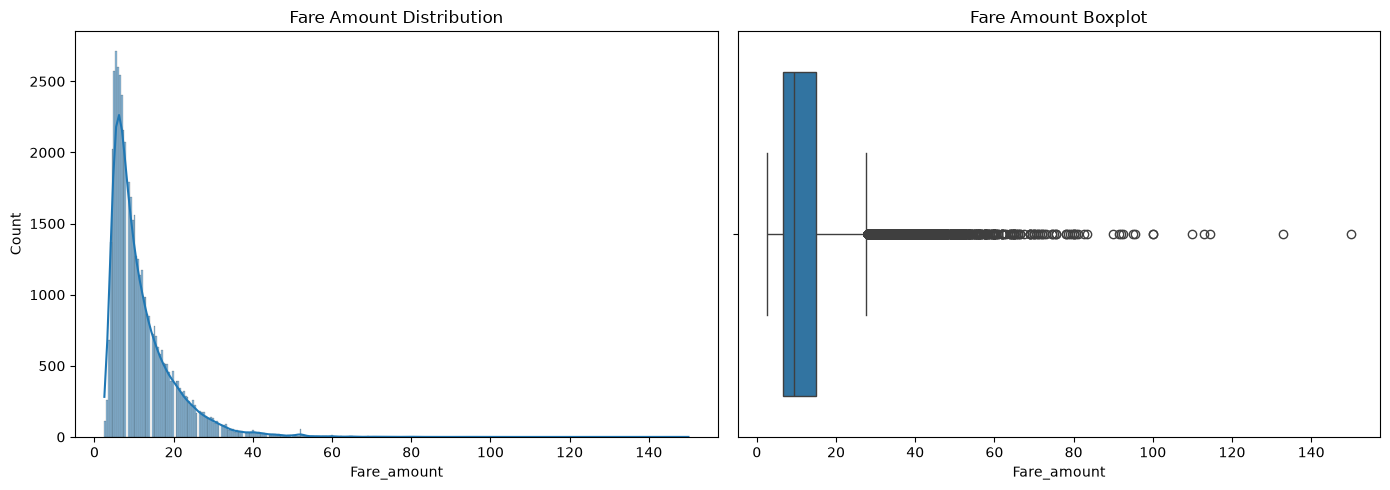

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create one figure with 2 graphs side by side (1 row, 2 columns), 14 x 5 inches
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left graph: histogram of fare. The bars show how many trips fall in each fare range; kde=True adds a smooth line.
sns.histplot(data=plot_df, x="Fare_amount", kde=True, ax=axes[0])

# Give the left graph a title
axes[0].set_title("Fare Amount Distribution")

# Right graph: boxplot of fare. The box is the middle 50% of trips; dots outside are unusually high fares.
sns.boxplot(data=plot_df, x="Fare_amount", ax=axes[1])

# Give the right graph a title
axes[1].set_title("Fare Amount Boxplot")

# Adjust spacing so the titles do not overlap
plt.tight_layout()

# Show the figure
plt.show()

<h3 style="color:green; font-weight:bold">5.2 — Trip Distance Analysis</h3>

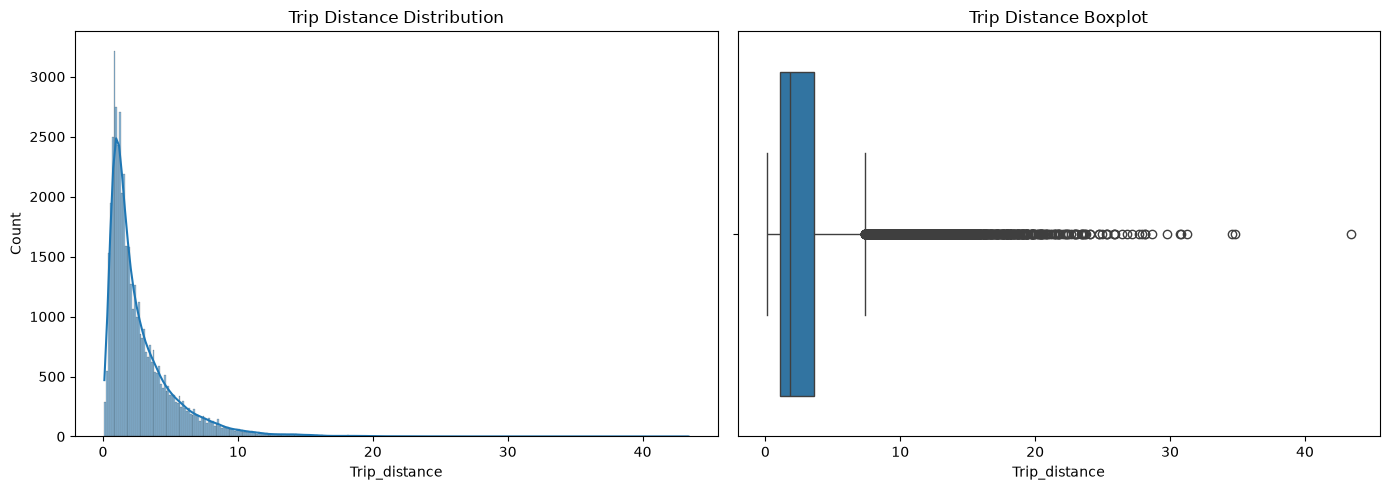

In [ ]:
# Create one figure with 2 graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left graph: histogram of trip distance
sns.histplot(data=plot_df, x="Trip_distance", kde=True, ax=axes[0])

# Give the left graph a title
axes[0].set_title("Trip Distance Distribution")

# Right graph: boxplot of trip distance
sns.boxplot(data=plot_df, x="Trip_distance", ax=axes[1])

# Give the right graph a title
axes[1].set_title("Trip Distance Boxplot")

# Adjust spacing so the titles do not overlap
plt.tight_layout()

# Show the figure
plt.show()

<h3 style="color:green; font-weight:bold">5.3 — Feature vs Target Analysis</h3>

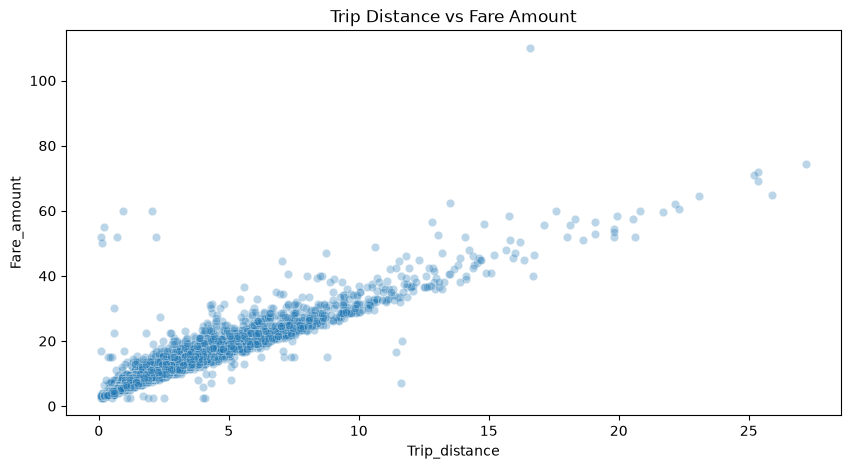

In [ ]:
# Make one figure of 10 x 5 inches
plt.figure(figsize=(10, 5))

# Scatter plot: every dot is one trip (distance on x, fare on y). We use 5,000 trips, alpha=0.3 makes dots see-through so crowded areas look darker.
sns.scatterplot(data=plot_df.sample(5000, random_state=42), x="Trip_distance", y="Fare_amount", alpha=0.3)

# Give the graph a title
plt.title("Trip Distance vs Fare Amount")

# Show the graph
plt.show()

In [ ]:
# Correlation: a number from -1 to 1 that shows how strongly two columns move together (1 = perfectly together)
print(df[["Trip_distance", "Fare_amount"]].corr())

               Trip_distance  Fare_amount
Trip_distance       1.000000     0.941331
Fare_amount         0.941331     1.000000


<h3 style="color:green; font-weight:bold">5.4 — Categorical Feature Analysis</h3>

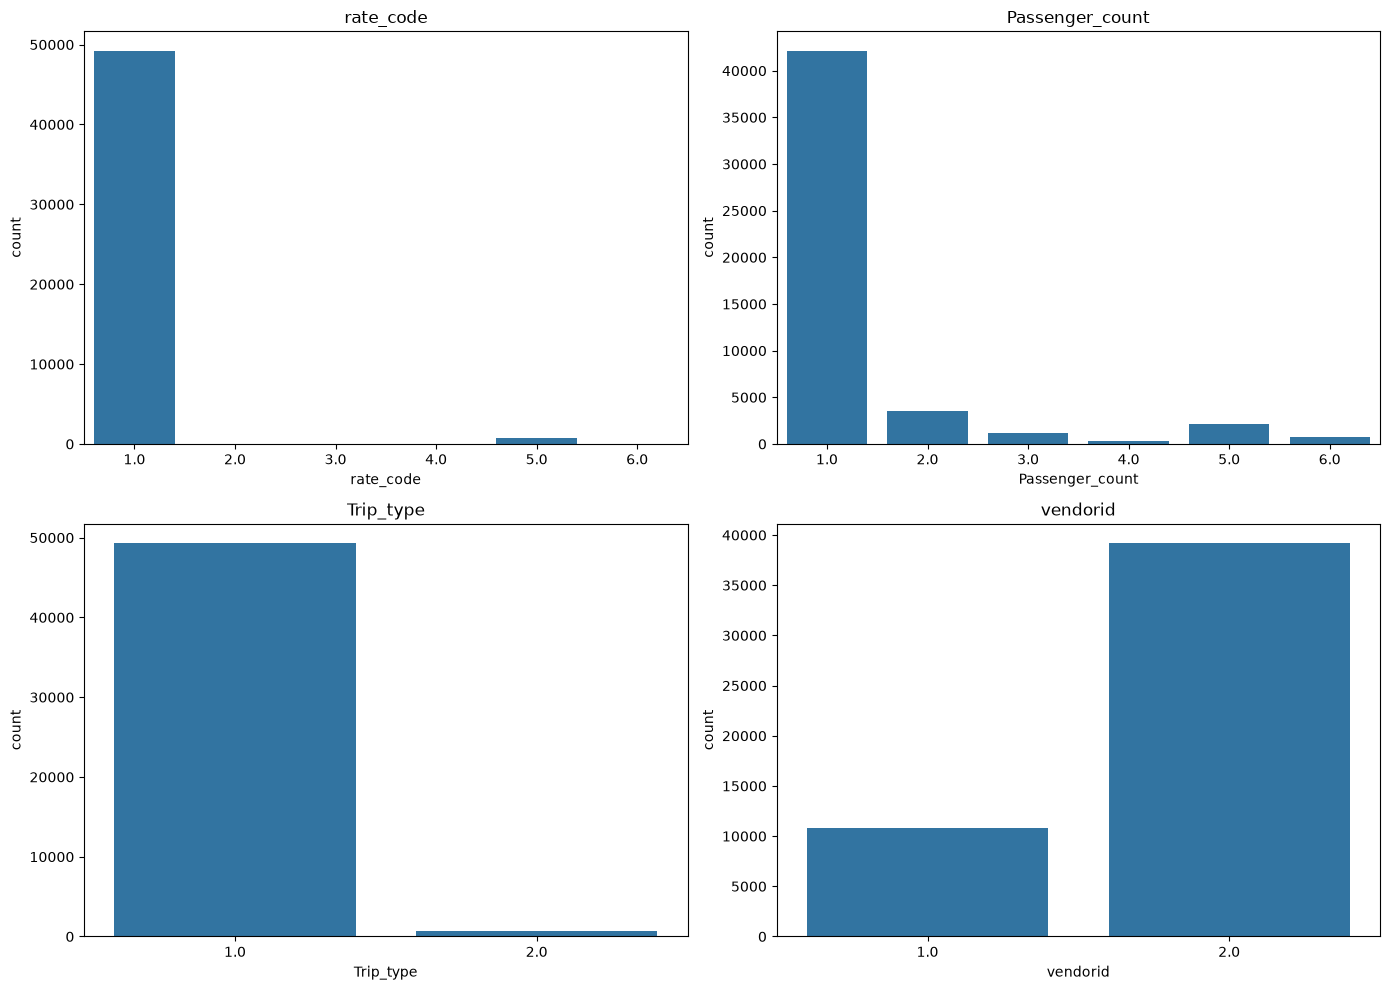

In [ ]:
# Create a 2 x 2 grid of graphs, 14 x 10 inches
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: how many trips per rate code (1 = standard, 2 = JFK, 3 = Newark, 4 = Nassau/Westchester, 5 = negotiated, 6 = group ride)
sns.countplot(data=plot_df, x="rate_code", ax=axes[0, 0])
axes[0, 0].set_title("rate_code")

# Top-right: how many trips per passenger count
sns.countplot(data=plot_df, x="Passenger_count", ax=axes[0, 1])
axes[0, 1].set_title("Passenger_count")

# Bottom-left: how many trips per trip type (1 = street hail, 2 = dispatch)
sns.countplot(data=plot_df, x="Trip_type", ax=axes[1, 0])
axes[1, 0].set_title("Trip_type")

# Bottom-right: how many trips per vendor
sns.countplot(data=plot_df, x="vendorid", ax=axes[1, 1])
axes[1, 1].set_title("vendorid")

# Adjust spacing so the titles do not overlap
plt.tight_layout()

# Show the figure
plt.show()

In [ ]:
# Average fare for each rate code, to see if the rate code changes the price
print(df.groupby("rate_code")["Fare_amount"].mean().round(2))

rate_code
1.0    11.81
2.0    52.00
3.0    62.40
4.0    42.51
5.0    17.51
6.0     3.17
Name: Fare_amount, dtype: float64


<h1 style="color:orange; font-weight:bold">Step 6 — Feature Engineering</h1>
`pickup_datetime` is text, and a model cannot learn from text. We turn it into two simple numbers: the hour of the day and the day of the week.

In [ ]:
# Convert the text date (like 02/10/2015 08:46:15 AM) into a real date-time. format tells pandas how the text is written.
# errors="coerce" turns any unreadable date into NaT (missing) instead of stopping with an error.
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

# Remove rows whose date could not be read
df = df.dropna(subset=["pickup_datetime"])

# Create pickup_hour: the hour of the day (0 to 23). Fares can differ at night, at rush hour, and so on.
df["pickup_hour"] = df["pickup_datetime"].dt.hour

# Create pickup_weekday: the day of the week (0 = Monday ... 6 = Sunday). Weekdays and weekends can behave differently.
df["pickup_weekday"] = df["pickup_datetime"].dt.day_of_week

In [ ]:
# Check which months exist in the data, to decide if a month feature is useful
print(df["pickup_datetime"].dt.month.value_counts().sort_index())

pickup_datetime
1      96660
2     644231
3         67
4         69
5         70
6         51
7         61
8         57
9         58
10        54
11        46
12        57
Name: count, dtype: int64


In [ ]:
# Average fare for each hour of the day, to see if the hour changes the fare
print(df.groupby("pickup_hour")["Fare_amount"].mean().round(2))

pickup_hour
0     11.77
1     11.51
2     11.65
3     12.07
4     12.71
5     14.40
6     15.05
7     13.39
8     13.02
9     12.74
10    12.41
11    12.33
12    12.34
13    12.34
14    12.48
15    12.34
16    12.15
17    11.88
18    11.53
19    11.17
20    10.99
21    11.12
22    11.52
23    11.62
Name: Fare_amount, dtype: float64


<h1 style="color:orange; font-weight:bold">Step 7 — Define Target</h1>

In [ ]:
# List of the columns we keep as inputs. We choose the columns we KEEP (instead of listing the ones to drop),
# so no unwanted column, especially the target, can slip into X by mistake.
features = [
    "vendorid",
    "rate_code",
    "Pickup_longitude",
    "Pickup_latitude",
    "Dropoff_longitude",
    "Dropoff_latitude",
    "Passenger_count",
    "Trip_distance",
    "Trip_type",
    "pickup_hour",
    "pickup_weekday",
]

# X is the table of input columns
X = df[features]

# y is the target column: the fare we want to predict
y = df["Fare_amount"]

# Check the shapes: X must have 11 columns and y must have one value per row
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (741481, 11)
y Shape: (741481,)


In [ ]:
# Leakage check: the target column must NOT be inside X. This must print False.
print("Is Fare_amount inside X?", "Fare_amount" in X.columns)

# Print the final list of input columns once more to see them clearly
print(X.columns.tolist())

Is Fare_amount inside X? False
['vendorid', 'rate_code', 'Pickup_longitude', 'Pickup_latitude', 'Dropoff_longitude', 'Dropoff_latitude', 'Passenger_count', 'Trip_distance', 'Trip_type', 'pickup_hour', 'pickup_weekday']


<h1 style="color:orange; font-weight:bold">Step 8 — Train–Test Split</h1>

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train : ", X_train.shape)
print("X_test  : ", X_test.shape)
print("y_train : ", y_train.shape)
print("y_test  : ", y_test.shape)

X_train :  (593184, 11)
X_test  :  (148297, 11)
y_train :  (593184,)
y_test  :  (148297,)


<h1 style="color:orange; font-weight:bold">Step 9 — Preprocessing</h1>

In [ ]:
numerical_columns = ["Pickup_longitude", "Pickup_latitude", "Dropoff_longitude", "Dropoff_latitude", "Passenger_count", "Trip_distance", "pickup_hour", "pickup_weekday"]
categorical_columns = ["vendorid", "rate_code", "Trip_type"]

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

Categorical Columns: ['vendorid', 'rate_code', 'Trip_type']
Numerical Columns: ['Pickup_longitude', 'Pickup_latitude', 'Dropoff_longitude', 'Dropoff_latitude', 'Passenger_count', 'Trip_distance', 'pickup_hour', 'pickup_weekday']


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline(steps=[
    ("Imputer", SimpleImputer(strategy="median")),
    ("Scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("Imputer", SimpleImputer(strategy="most_frequent")),
    ("Encoder", OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("Numerical Pipeline", numerical_pipeline, numerical_columns),
    ("Categorical Pipeline", categorical_pipeline, categorical_columns)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Pipeline', ...), ('Categorical Pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transfo

<h1 style="color:orange; font-weight:bold">Step 10 — Model Comparison & Best Model Finding</h1>

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Models
ridge_pipeline = Pipeline(steps=[
    ("Preprocessor", preprocessor),
    ("Model", Ridge())
])

rf_pipeline = Pipeline(steps=[
    ("Preprocessor", preprocessor),
    ("Model", RandomForestRegressor(
        #n_estimators=100,
        n_estimators=10,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline(steps=[
    ("Preprocessor", preprocessor),
    ("Model", XGBRegressor(
        #n_estimators=100,
        n_estimators=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Models dictionary
models = {
    "Ridge Regression": ridge_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

results = []

# Train, Cross Validate and Evaluate
for name, model in models.items():

    # 5-Fold Cross Validation
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    # Train on complete training data
    model.fit(X_train, y_train)

    # Test predictions
    y_pred = model.predict(X_test)

    # Store results
    results.append({
        "Model": name,
        "CV RMSE Mean": -cv_scores.mean(),
        "CV RMSE Std": cv_scores.std(),
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Test R2": r2_score(y_test, y_pred)
    })

# Comparison table
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="CV RMSE Mean",
    ascending=True
)

print(comparison_df.to_string(index=False))

           Model  CV RMSE Mean  CV RMSE Std  Test MAE  Test RMSE  Test R2
   Random Forest      2.474310     0.046129  1.169440   2.425804 0.918690
         XGBoost      2.581269     0.058557  1.243247   2.547481 0.910328
Ridge Regression      2.834525     0.063907  1.455870   2.780867 0.893145


<h1 style="color:orange; font-weight:bold">Step 11 — HyperParameter Tunning</h1>

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from scipy.stats import randint

# Pipeline
rf_pipeline = Pipeline(steps=[
    ("Preprocessor", preprocessor),
    ("Model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameter search space
# param_dist = {
#     'Model__n_estimators'       : [100,200,300],
#     'Model__max_depth'          : [5,10,15],
#     'Model__min_samples_split'  : [2,5,10],
#     'Model__min_samples_leaf'   : [1,2,4]
# }

param_dist = {
    'Model__n_estimators': [10, 20],
    'Model__max_depth': [2, 5]
}

# Randomized Search CV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=4,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Fit
random_search.fit(X_train, y_train)

# Best model
best_rf_model = random_search.best_estimator_

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

# Test evaluation
y_pred = best_rf_model.predict(X_test)

print("\nTest MAE:", mean_absolute_error(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R2:", r2_score(y_test, y_pred))

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters:
{'Model__n_estimators': 10, 'Model__max_depth': 5}

Best CV RMSE:
2.7495164412471524

Test MAE: 1.4498698371734853
Test RMSE: 2.7055069348463756
Test R2: 0.8988579241478649
